# Segment subject brain according to the MultiConn atlas

To use the MultiConn atlas, one must segment individual brains according to the parcellation used in [Alemán-Gómez et. al 2022](https://www.nature.com/articles/s41597-022-01624-8).

The MultiConn's parcellation is a combination of the cortical parcellation from [Cammoun et al. 2012]() and the subcortical parcellation from [Battistella et al. 2016](https://link.springer.com/article/10.1007/s00429-016-1336-4).

In this evaluation, we first generate the cortical and subcortical parcellations, and then use the Parcellation class to combine both into the MultiConn's parcellation.

The following process can be run with `mindmap.prior.make_MultiConn(...)`

## Imports

In [1]:
import mindmap as mm

mm.io.read_config("../configurations/spike.yml", env=True)

## Data

In [2]:
subject = "sub-pat09"
scale   = 4

# files
atlasL      = f'/home/admin/work/data/atlas/laus2018/lh.atlas-laus2018_desc-scale{scale}.annot'
atlasR      = f'/home/admin/work/data/atlas/laus2018/rh.atlas-laus2018_desc-scale{scale}.annot'
parc_atlas  = '/home/admin/work/data/atlas/Thalamic_Nuclei/Thalamus_Nuclei-HCP-4DSPAMs.nii.gz'
clut        = '/home/admin/work/data/atlas/Thalamic_Nuclei/Thalamic_Nuclei-ColorLUT.txt'
ref_atlas   = '/home/admin/work/data/atlas/mni_icbm152_nlin_asym_09c_nifti/mni_icbm152_nlin_asym_09c/mni_icbm152_t1_tal_nlin_asym_09c.nii'
wmparc_dmax = 2
thresh      = 0.05

## Generate cortical and subcortical parcellations

Run time: 4 min (+1 if visualizing)

In [3]:
# make cortical parcellation (3 min)
laus2018 = mm.utils.make_dparc(
    subject     = subject,
    atlasL      = atlasL,
    atlasR      = atlasR,
    wmparc_dmax = wmparc_dmax,
)
laus2018.change_ids([(3001, 3999), (4001, 4999)], lambda x: x-2000)      # change white matter ids to grey matter ids

# make sub-cortical parcellation (1 min)
thal = mm.utils.make_pparc(
    subject    = subject,
    parc_atlas = parc_atlas,
    ref_atlas  = ref_atlas,
    clut       = clut,
)
thal = thal.prob2dseg(thresh=thresh)         # convert probability volume to deterministic volume

Generating deterministic parcellation for subject sub-pat09...
Generating probability parcellation for sub-pat09 ...


In [4]:
image_laus = laus2018.get_image()   # (1 min)
image_thal = thal.get_image()

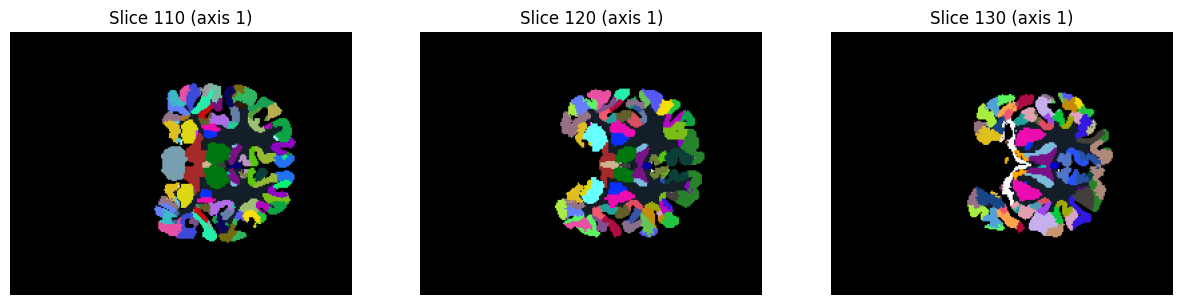

In [5]:
slices = [110, 120, 130]
mm.viz.show_slices(image_laus, slices, axis=1)

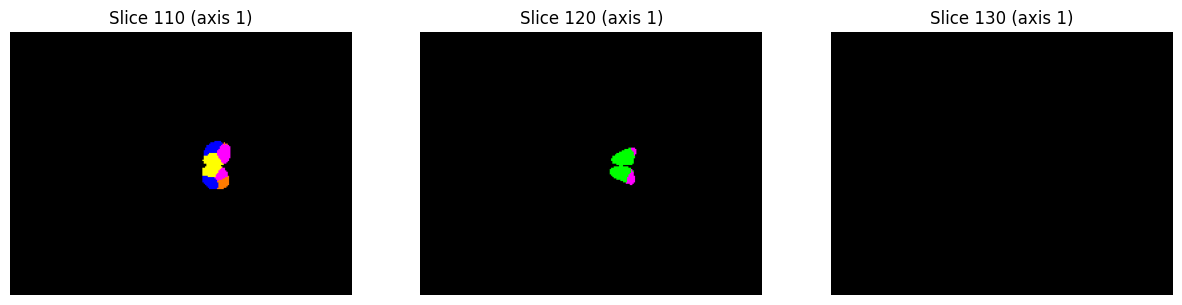

In [6]:
mm.viz.show_slices(image_thal, slices, axis=1)

## Combine cortical and subcortical parcellations
Run time: 1 min

In [7]:
# Extract and rename parts of interest from the Lausanne 2018 parcellation.
ctx_lh = laus2018.retain([(1001, 1999), (3001, 3999)])
ctx_lh.change_labels(prefix="ctx-lh-")

ctx_rh = laus2018.retain([(2001, 2999), (4001, 4999)])
ctx_rh.change_labels(prefix="ctx-rh-")

subc_lh = laus2018.retain([11, 12, 13, 26, 18, 17])
subc_lh.change_labels(replace={"Left-":"", "Accumbens-area":"accumbens_area"}, prefix="subc-lh-", lower=True)

subc_rh = laus2018.retain([50, 51, 52, 58, 54, 53])
subc_rh.change_labels(replace={"Right-":"", "Accumbens-area":"accumbens_area"}, prefix="subc-rh-", lower=True)

# Extract and rename parts of interest from the thalamic parcellation.
thal_lh = thal.retain([(8, 14)])

thal_rh = thal.retain([(1,7)])

brain_stem = laus2018.retain([16])
brain_stem.change_labels(replace={"-":"_"})

# join parts of interest
multi_conn = mm.utils.Parcellation()
multi_conn = multi_conn.join(ctx_rh)
multi_conn = multi_conn.join(thal_rh)
multi_conn = multi_conn.join(subc_rh)
multi_conn = multi_conn.join(ctx_lh)
multi_conn = multi_conn.join(thal_lh)
multi_conn = multi_conn.join(subc_lh)
multi_conn = multi_conn.join(brain_stem)

In [8]:
image_multiconn = multi_conn.get_image()

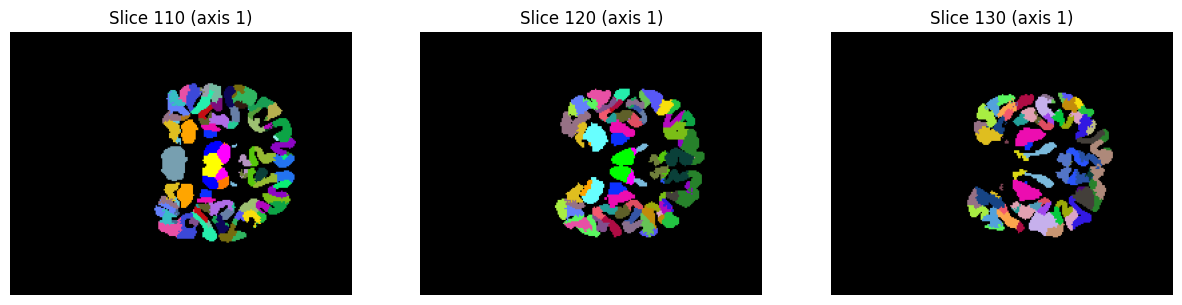

In [9]:
mm.viz.show_slices(image_multiconn, slices, axis=1)

## Saving parcellation

In [10]:
# save the parcellation
from pathlib import Path
import os

folder = Path(os.environ["MM_DIR"])/subject/"parc"       # folder name


if folder.exists() == False:
    folder.mkdir(parents=True)

print(f"Saving parcellation for subject: {subject}")
multi_conn.save(
    folder/f"{subject}_multiConn{scale}-{wmparc_dmax}-{thresh}_dparc.nii.gz",
    folder/f"{subject}_multiConn{scale}-{wmparc_dmax}-{thresh}_clut.txt",
)

Saving parcellation for subject: sub-pat09


In [11]:
import pandas as pd

pd.set_option("display.max_rows", None)
multi_conn.get_clut()

,#No.,Label name,R,G,B,A
0,1,ctx-rh-lateralorbitofrontal_1,122,66,82,0.0
1,2,ctx-rh-lateralorbitofrontal_2,39,183,31,0.0
2,3,ctx-rh-lateralorbitofrontal_3,251,178,203,0.0
3,4,ctx-rh-lateralorbitofrontal_4,117,132,211,0.0
4,5,ctx-rh-lateralorbitofrontal_5,193,7,120,0.0
5,6,ctx-rh-lateralorbitofrontal_6,128,239,62,0.0
6,7,ctx-rh-lateralorbitofrontal_7,218,98,158,0.0
7,8,ctx-rh-parsorbitalis_1,209,251,121,0.0
8,9,ctx-rh-parsorbitalis_2,69,53,62,0.0
9,10,ctx-rh-frontalpole_1,134,248,137,0.0
